# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAMES = "Ali, Olivia, Will"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


{0: 'TV', 1: 'baby_monitor', 2: 'lights', 3: 'motion_sensor', 4: 'security_camera', 5: 'smoke_detector', 6: 'socket', 7: 'thermostat', 8: 'watch'}


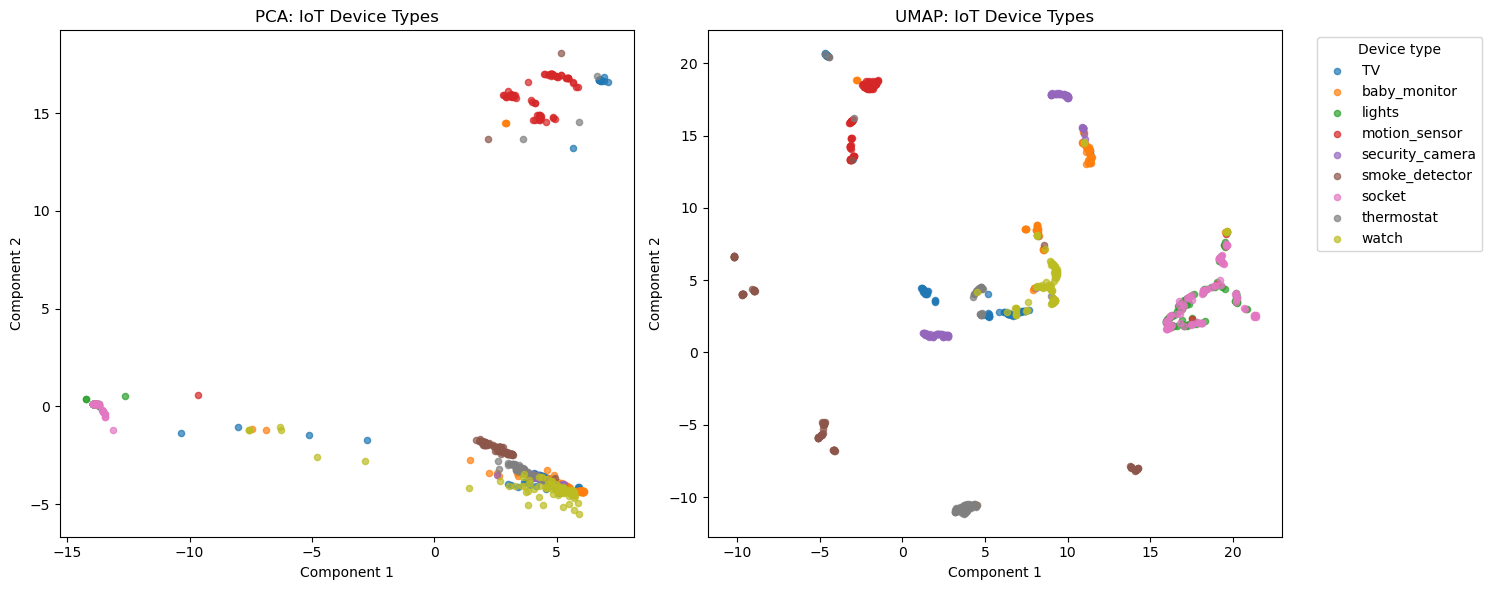

In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from umap import UMAP

#1

df_train = pd.read_csv("iot_devices_train.csv")
df_report = pd.read_csv("iot_devices_reporting.csv")

#2

X_train = df_train.drop(columns="device_category")
y_train = df_train["device_category"]

X_report = df_report.drop(columns="device_category")
y_report = df_report["device_category"]

#3

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_report = label_encoder.transform(y_report)

# show which number is each device type
print(dict(enumerate(label_encoder.classes_)))

#4

pca_pipeline = make_pipeline(
    StandardScaler(),
    PCA(n_components=2)
)

umap_pipeline = make_pipeline(
    StandardScaler(),
    UMAP(n_components=2, random_state=42, n_jobs=1)
)

X_pca = pca_pipeline.fit_transform(X_train)
X_umap = umap_pipeline.fit_transform(X_train)

#5 graphs

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = plt.get_cmap("tab10")

for ax, embedding, title in zip(
    axes,
    [X_pca, X_umap],
    ["PCA", "UMAP"]
):
    for label, device in enumerate(label_encoder.classes_):
        mask = y_train == label

        ax.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            color=colors(label),
            label=device,
            s=20,
            alpha=0.7
        )

    ax.set_title(f"{title}: IoT Device Types")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

axes[1].legend(
    title="Device type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()




#6

PCA seperates some groups, such as many motion monitor sensors near the top, but several device categories overlap by a lot in the lower right of the plot. UMAP looks to spread the data into more distinct groups, which to us, makes the local structure easier to see. For example may thermostats for a compact cluster in the top right, while smoke detectors appear in seperate groups on the left. However, lights and sockets still overlap, which might suggest similar traffic features. Some device types also split into multiple clusters, which could indicate a range of traffic behaviors in one specific category. Overall we think that UMAP gives a clearer view of the device groupings while PCA shows broader variation and less seperation between groups. 

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

3. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

4. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

5. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
6. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

1. For tree-based methods, standardization is not needed as the model is training on one feature at a time. For neural networks, standardization is needed as it works with activation functions, etc - Random forest and gradient boosting don't need standardization or normalization because their decision trees split induvidual features using thresholds. Different feature scales therefore don't affect them in the same way the affect distance based models or nueral networks. Our input features are already numeric including the catagorical column (done in part 1) and neither dataset contains missing values so no additional feature encoing or imputation would be needed. We will keep the consistent target-label encoding from part 1 and train these models using the original unscaled features. The standardized pca and UMAP stuff was just for visualization. 

In [15]:
# 2

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from time import time

# reusing this object for both models and later parts
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# same 3 candidates for both models
depth_values = [3, 5, 10]

param_grid = {
    "max_depth": depth_values,
    "learning_rate": [0.01, 0.1, 0.3]
}

rf_param_grid = {
    "max_depth": depth_values,
    "max_features": ["sqrt", "log2", 0.5]
}

# running the gradient boosting search

gb_search = GridSearchCV(
    estimator=GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start = time()
gb_search.fit(X_train, y_train)
gb_minutes = (time() - start) / 60

print("Gradient Boosting")
print("Best parameters-", gb_search.best_params_)
print(f"Best mean CV accuracy- {gb_search.best_score_:.2%}")
print(f"Total fitting time- {gb_minutes:.3f} minutes")

# the random forest search

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start = time()
rf_search.fit(X_train, y_train)
rf_minutes = (time() - start) / 60

print("Random Forest")
print("Best parameters:", rf_search.best_params_)
print(f"Best mean CV accuracy: {rf_search.best_score_:.2%}")
print(f"Total fitting time: {rf_minutes:.3f} minutes")

Gradient Boosting
Best parameters- {'learning_rate': 0.1, 'max_depth': 3}
Best mean CV accuracy- 89.00%
Total fitting time- 0.857 minutes
Random Forest
Best parameters: {'max_depth': 10, 'max_features': 0.5}
Best mean CV accuracy: 88.89%
Total fitting time: 0.036 minutes


Gradient Boosting
Reporting accuracy- 68.78%
Total hyperparameter search time- 0.857 minutes
                 precision    recall  f1-score   support

             TV      0.497     0.780     0.607       100
   baby_monitor      0.961     0.740     0.836       100
         lights      0.690     0.490     0.573       100
  motion_sensor      0.940     0.630     0.754       100
security_camera      0.919     0.340     0.496       100
 smoke_detector      1.000     1.000     1.000       100
         socket      0.592     0.770     0.670       100
     thermostat      0.652     0.920     0.763       100
          watch      0.433     0.520     0.473       100

       accuracy                          0.688       900
      macro avg      0.743     0.688     0.686       900
   weighted avg      0.743     0.688     0.686       900

Random Forest
Reporting accuracy- 58.00%
Total hyperparameter search time- 0.036 minutes
                 precision    recall  f1-score   support

             TV 

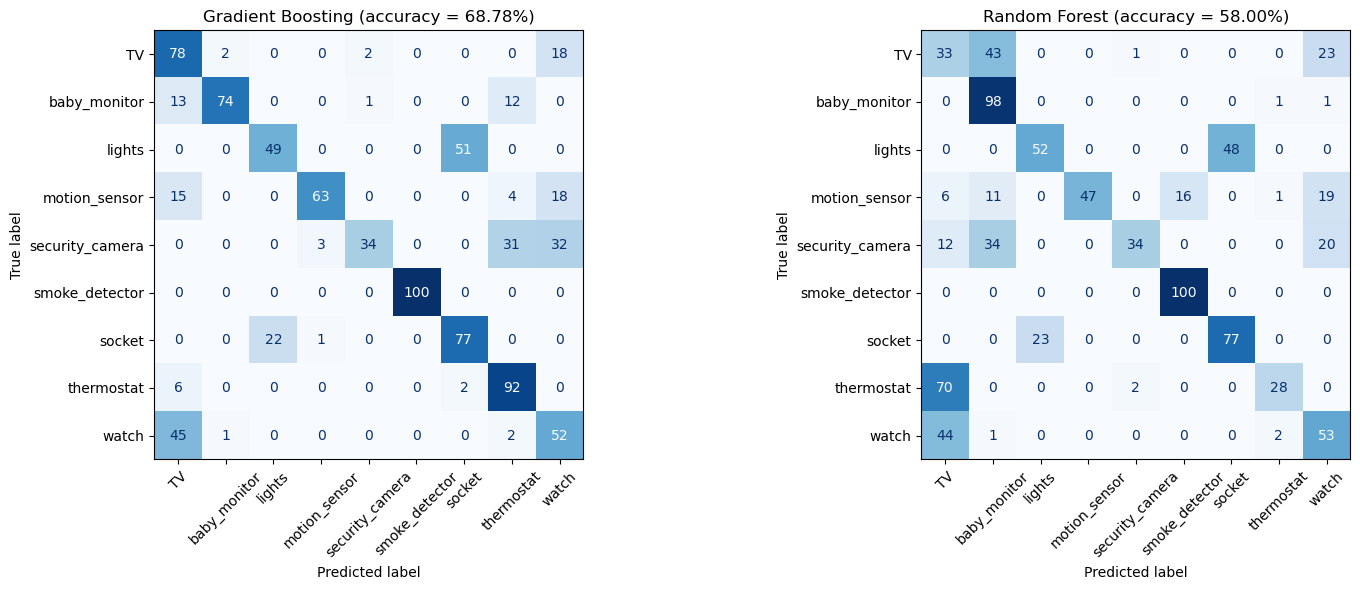

In [16]:
# 3

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

models = {
    "Gradient Boosting": (gb_search.best_estimator_, gb_minutes),
    "Random Forest": (rf_search.best_estimator_, rf_minutes),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, (model, minutes)) in zip(axes, models.items()):
    y_pred = model.predict(X_report)
    acc = accuracy_score(y_report, y_pred)

    print(name)
    print(f"Reporting accuracy- {acc:.2%}")
    print(f"Total hyperparameter search time- {minutes:.3f} minutes")
    print(classification_report(y_report, y_pred, target_names=label_encoder.classes_, digits=3))

    cm = confusion_matrix(y_report, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=label_encoder.classes_).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
    )
    ax.set_title(f"{name} (accuracy = {acc:.2%})")

plt.tight_layout()
plt.show()


Gradient Boosting reached an accuracy of 68.8% on the reporting set, while Random Forest reached an accuracy of 58.0%. Both had an 89% in cross-validation, however, So, the large gap suggests tht our reporting data differs from the training data in some ways, so the CV score overestimates how well the models generalize. Gradient Boosting performed better in terms of generaization, however its hyperparameter search took a lot longer than Random Forest. Gradient Boosting's hyperparameter search took 0.862 minutes, while Random Forest's took 0.036 minutes, giving a gap of 0.862 minutes. The easiest devices to classify are smoke detectors, which were classified 100% correctly by both of the models. Both of the models also did well classifying sockets. Gradient Boosting classified thermostats and TVs well as well, at 92% and 78%. Random Forest classified baby monitors well at 98%. Lights and sockets were more difficult to classeify. Almost half of the lights were predicted as sockets, so they were confused with each other. Watches and TVs were also harder to classify as these were also mixed/confused with each other as well. Security cameras were also hard to classify as they were scattered across thermostats, watch, or baby monitors, TV and watch. Random Forest struggled with this a lot has most thermostats were misclassified as TVs and almost half of the TVs were classified as baby monitors. 

Cosine similarity- 0.558
Pearson correlation- 0.514
Spearman rank correlation- 0.868
Top-10 overlap- 4/10: ['packet_inter_arrivel_A_sum', 'packet_inter_arrivel_B_min', 'packet_inter_arrivel_sum', 'ttl_min']
Top-20 overlap- 8/20: ['packet_inter_arrivel_A_sum', 'packet_inter_arrivel_B_min', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_entropy', 'ttl_max', 'ttl_min']
Features with zero importance- GB: 153  RF: 148


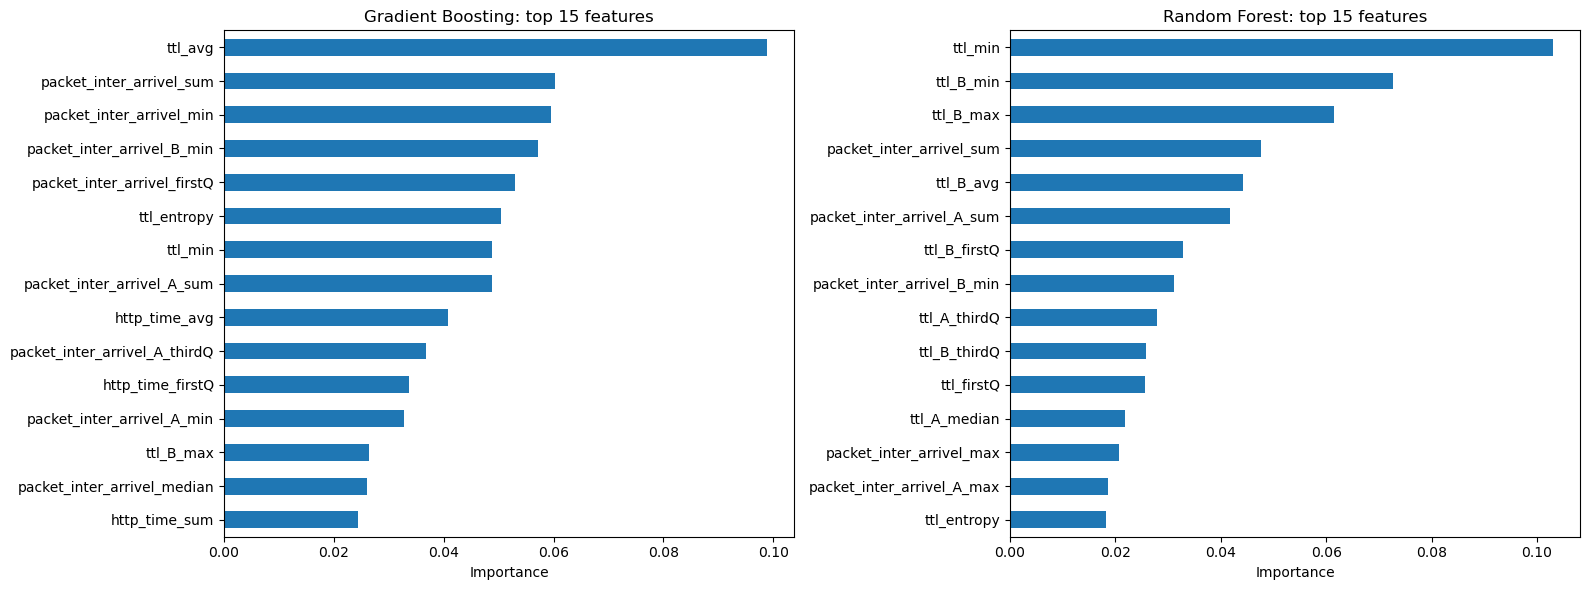

In [17]:
# 4
from scipy.stats import pearsonr, spearmanr

gb_imp = gb_search.best_estimator_.feature_importances_
rf_imp = rf_search.best_estimator_.feature_importances_

importances = pd.DataFrame({"Gradient Boosting": gb_imp, "Random Forest": rf_imp},
                           index=X_train.columns)

# quantitative similarity between the two importance vectors
cosine = gb_imp @ rf_imp / (np.linalg.norm(gb_imp) * np.linalg.norm(rf_imp))
print(f"Cosine similarity- {cosine:.3f}")
print(f"Pearson correlation- {pearsonr(gb_imp, rf_imp)[0]:.3f}")
print(f"Spearman rank correlation- {spearmanr(gb_imp, rf_imp)[0]:.3f}")

for k in [10, 20]:
    gb_top = set(importances["Gradient Boosting"].nlargest(k).index)
    rf_top = set(importances["Random Forest"].nlargest(k).index)
    print(f"Top-{k} overlap- {len(gb_top & rf_top)}/{k}: {sorted(gb_top & rf_top)}")

print("Features with zero importance- GB:", (gb_imp == 0).sum(), " RF:", (rf_imp == 0).sum())

# qualitative comparison: top 15 features of each model side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col in zip(axes, importances.columns):
    importances[col].nlargest(15).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{col}: top 15 features")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


Both of these models mainly depend on two types of features which are TTL statistics and packet inter-arrival time statistics. Neither of the models uses about half of the features, so a lot of the dataset is redundant. Quantitatively, the Spearman rank correlation between the two importance vectors is high at 0.87, so the models mostly agree on which features matter versus the ones that don't The cosine similarity was 0.56 and the Pearson correlation was 0.51. These are moderate, so they disagree on how much weight each of the top features gets. Only four of their top 10 features overlap. This includes the ttl_min, packet_inter_arrivel_sum, packet_inter_arrivel_A_sum, and packet_inter_arrival_B_min. because Random Forest trees only sees a subset of features which are random, whichever version that is available is used so importance is spread across a lot of correlated versions of the same signal. Gradient Boosting builds trees one after another, after learning from the previous tree's errors, so it picks one strong feature from a correlated group and then moves onto features to fix the remaining errors. So, Random Forest uses a lot of min, max, and averages of TTL while Gradient Boosting uses a lot of inter-arrival times and http_time features. 

5. 

The dataset has 9 balanced device classes, so if we were random guessing, we would expect about 1/9 or 11% in accuracy as our baseline. Gradient Boosting reached an accuracy of 68.8% and Random Forest reached an accuracy of 58%. These are much better accuracies than randomly guessing when compared to the 11% baseline. 

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

In [18]:
# 1

In [ ]:
# 2
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_search = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        max_iter=100,      
        random_state=42
    ),
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start = time()
hgb_search.fit(X_train, y_train)
hgb_minutes = (time() - start) / 60

print("Histogram-Based Gradient Boosting")
print("Best parameters-", hgb_search.best_params_)
print(f"Best mean CV accuracy- {hgb_search.best_score_:.2%}")
print(f"Total fitting time- {hgb_minutes:.3f} minutes")


c:\Users\olivi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\olivi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\olivi\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\olivi\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\olivi\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Histogram-Based Gradient Boosting
Best parameters- {'learning_rate': 0.01, 'max_depth': 10}
Best mean CV accuracy- 87.89%
Total fitting time- 1.207 minutes


Histogram-Based Gradient Boosting
Reporting accuracy- 69.11%
Total hyperparameter search time- 1.207 minutes
                 precision    recall  f1-score   support

             TV      0.493     0.660     0.564       100
   baby_monitor      0.953     0.810     0.876       100
         lights      0.700     0.490     0.576       100
  motion_sensor      0.705     0.670     0.687       100
security_camera      0.944     0.340     0.500       100
 smoke_detector      0.962     1.000     0.980       100
         socket      0.598     0.790     0.681       100
     thermostat      0.732     0.900     0.807       100
          watch      0.463     0.560     0.507       100

       accuracy                          0.691       900
      macro avg      0.728     0.691     0.687       900
   weighted avg      0.728     0.691     0.687       900



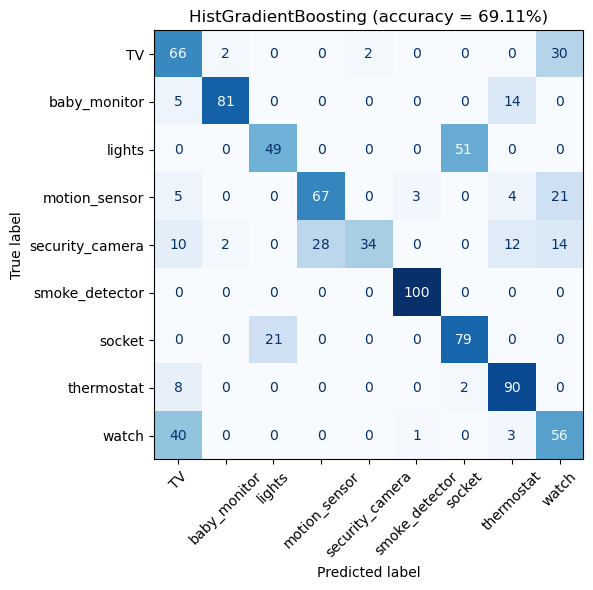

                                                   Best params  CV accuracy  \
GradientBoosting        {'learning_rate': 0.1, 'max_depth': 3}     0.890000   
HistGradientBoosting  {'learning_rate': 0.01, 'max_depth': 10}     0.878889   

                      Reporting accuracy  Search time (min)  
GradientBoosting                0.687778           0.856758  
HistGradientBoosting            0.691111           1.207470  


In [21]:
# 3
hgb_best = hgb_search.best_estimator_
y_pred_hgb = hgb_best.predict(X_report)
hgb_acc = accuracy_score(y_report, y_pred_hgb)

print("Histogram-Based Gradient Boosting")
print(f"Reporting accuracy- {hgb_acc:.2%}")
print(f"Total hyperparameter search time- {hgb_minutes:.3f} minutes")
print(classification_report(y_report, y_pred_hgb, target_names=label_encoder.classes_, digits=3))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix(y_report, y_pred_hgb),
                       display_labels=label_encoder.classes_).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title(f"HistGradientBoosting (accuracy = {hgb_acc:.2%})")
plt.tight_layout()
plt.show()

gb_acc = accuracy_score(y_report, gb_search.best_estimator_.predict(X_report))
print(pd.DataFrame({
    "Best params": [gb_search.best_params_, hgb_search.best_params_],
    "CV accuracy": [gb_search.best_score_, hgb_search.best_score_],
    "Reporting accuracy": [gb_acc, hgb_acc],
    "Search time (min)": [gb_minutes, hgb_minutes],
}, index=["GradientBoosting", "HistGradientBoosting"]))


4. The Histogram Gradient Boosting performed similarly to the Gradient Boosting. The reporting set accuracy was 69.1% while Gradient Boosting's was 68.8%. In cross-validation, Gradient boosting did slightly better at 89% compared to Histogram Gradient Boosting's 87.9%. The confusion matrices are also similar. Smoke detectors and thermostats were easy to classify for both of these models. Lights and sockets and watches and TVs were mixed up for both. Security cameras were also the hardest to classify for both of these models. Histogram Gradient Boosting, however, misclassified security cameras as motion sensors more, but Gradient Boosting classified them as thermostats or watches. A tradeoff is that Histogram Gradeint Boosting is less sensitive to hyperparameters as all 9 combinations scored between an 86.4% and 87.9% in CV. Another tradeoff is that Gradient Boosting was faster than Histogram Gradient Boosting. Histogram Gradient Boosting has advantages, like handling missing values natively, which Gradient Boosting does not do. The cost would be a small loss of precision from the binning, which can matter when a class depends on fine differences in feature values. However, in this situation, Gradient Boosting was faster and performed similarly well to Histogram Gradient Boosting.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE